In [29]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features 


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
selection = data.selectionner(
    sources=("12kDE", "12kFE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7, 14, 21), positions_or=("6",),
    charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "12kFE": ("FE",), 
            "Normal": ("DE","FE")},
)

In [31]:
# Importation des données sélectionnées et ajout des indicateurs temporels et spectraux
table = features.construire_table(selection, data.charger)

In [32]:
# Visu dataset
# table.iloc[70:100, :15]
#  from Sources.indicateurs import COLONNES_INDICATEURS


table[indicateurs.COLONNES_INDICATEURS]

# display(table.groupby(["source", "classe", "canal"]).size().unstack())
# table.defaut.unique()

,RMS,Pic,Crete,Kurtosis,amp_BPFI_1,amp_BPFI_2,amp_BPFI_3,amp_BPFO_1,amp_BPFO_2,amp_BPFO_3,amp_BSF_1,amp_BSF_2,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF
0,0.073348,0.272869,3.720207,2.859637,0.001597,0.002058,0.001628,0.003195,0.000803,0.002058,0.001042,0.002046,0.000695,0.005129,0.018184,0.017151,0.145663,0.291477,0.095059,0.467801
1,0.078434,0.226765,2.891156,2.863790,0.001803,0.002043,0.001077,0.002399,0.002057,0.002494,0.002282,0.003001,0.001007,0.003921,0.018263,0.017174,0.173300,0.230523,0.219351,0.376826
2,0.073608,0.249295,3.386784,2.794364,0.000947,0.001775,0.000846,0.002880,0.000965,0.001775,0.001671,0.002400,0.002748,0.001492,0.021490,0.021453,0.135454,0.412018,0.239091,0.213438
3,0.073188,0.247418,3.380577,2.935528,0.001733,0.002494,0.001882,0.003540,0.001379,0.002494,0.002116,0.003701,0.001035,0.003435,0.020528,0.020191,0.160060,0.327051,0.195506,0.317384
4,0.071653,0.224679,3.135669,2.833588,0.001251,0.002248,0.002444,0.001622,0.002042,0.002648,0.001938,0.000889,0.000518,0.005197,0.021073,0.022591,0.124962,0.162112,0.193647,0.519279
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4712,0.853432,4.829956,5.659448,9.060737,0.096229,0.010138,0.026599,0.476423,0.170636,0.042710,0.249952,0.033822,0.063823,0.056750,0.586948,0.669555,0.109431,0.541788,0.284245,0.064536
4713,0.746545,3.710066,4.969648,6.040556,0.139856,0.030942,0.014493,0.462302,0.147949,0.016370,0.068738,0.076552,0.028864,0.029306,0.318542,0.330890,0.199736,0.660242,0.098169,0.041853
4714,0.842788,4.796217,5.690893,10.128908,0.164481,0.014571,0.017496,0.465132,0.115394,0.061827,0.292404,0.059872,0.022011,0.019165,0.560075,0.656948,0.174760,0.494200,0.310677,0.020363
4715,0.862945,5.028325,5.826934,9.129749,0.098537,0.020324,0.016569,0.491023,0.172454,0.045211,0.273691,0.048348,0.047168,0.030995,0.583986,0.674855,0.110190,0.549091,0.306058,0.034660


In [33]:
# Preparation pour le modeling
#| label: preparation-modeling
#| code-summary: "Split par fichier + standardisation"
#| tbl-cap: "Répartition des fichiers entre apprentissage et test."

# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling(table, COLONNES_INDICATEURS)
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, indicateurs.COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target="defaut")

print("##########################################")
print("######### Table d'apprentissage ##########")
print("##########################################")
print("1. Split Train => DE, Test => FE")
print("2. Répartition des classes du train")

# Équilibre UNIQUEMENT le train (le test reste complet)
X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

print("##########################################")
print("############### Features #################")
print("##########################################")
X_train.head()

##########################################
######### Table d'apprentissage ##########
##########################################
1. Split Train => DE, Test => FE
2. Répartition des classes du train


,train,test
defaut,,
Sain,601,706
IR,601,600
B,601,600
OR,601,300


##########################################
############### Features #################
##########################################


,RMS,Pic,Crete,Kurtosis,amp_BPFI_1,amp_BPFI_2,amp_BPFI_3,amp_BPFO_1,amp_BPFO_2,amp_BPFO_3,amp_BSF_1,amp_BSF_2,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF
780,-0.847735,-0.781768,-0.780604,-0.650465,-0.725800,-0.725966,-0.603650,-0.565136,-0.585202,-0.725911,-0.620317,-0.919308,-0.601615,-0.787837,-0.652614,-0.651592,-0.224303,-0.913742,1.224345,0.671216
81,-0.796443,-0.779470,-0.980288,-0.686600,-0.730638,-0.716700,-0.596515,-0.548613,-0.576415,-0.716646,-0.608321,-0.761304,-0.616449,-0.659176,-0.539195,-0.549444,-1.142964,-0.212722,-0.232075,1.838096
77,-0.783754,-0.777603,-1.009861,-0.688146,-0.725264,-0.723930,-0.599593,-0.549732,-0.578699,-0.723875,-0.603641,-0.931533,-0.596463,-0.671538,-0.531648,-0.538230,-0.961148,-0.304105,0.019669,1.573235
309,-0.822640,-0.769992,-0.777564,-0.670050,-0.730716,-0.725472,-0.609288,-0.561481,-0.574960,-0.725417,-0.615008,-0.936464,-0.629029,-0.732258,-0.625770,-0.626069,-0.923070,-0.752710,0.543722,1.751643
621,-0.841750,-0.743998,-0.405766,-0.629525,-0.731696,-0.735625,-0.580797,-0.565026,-0.573764,-0.735569,-0.626604,-0.864944,-0.626332,-0.783576,-0.643557,-0.643883,-0.620246,-0.757983,0.732337,1.266960


In [34]:
#| label: regression logistique
from sklearn import linear_model

logreg = linear_model.LogisticRegression(max_iter=500, random_state=24)
logregb = linear_model.LogisticRegression(max_iter=500, random_state=24, class_weight="balanced") ##  >> Pour gérer le déséquilibre de classes

logreg.fit(X_train, y_train)
logregb.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_predb = logregb.predict(X_test)
cm = pd.crosstab(y_test, y_pred, rownames=['Classe réelle'], colnames=['Classe prédite'])
cmb = pd.crosstab(y_test, y_predb, rownames=['Classe réelle'], colnames=['Classe prédite'])

In [35]:
#| label: regression logistique pour avoir une base, avec comparaison class_weight="balanced" ou non
from sklearn.metrics import classification_report
print("##########################################")
print("############# LogReg standard ############")
print("##########################################")

display(cm)
print(classification_report(y_test, y_pred))

print("##########################################")
print("###### LogReg class_weight=balanced ######")
print("##########################################")

display(cmb)
print(classification_report(y_test, y_predb))

##########################################
############# LogReg standard ############
##########################################


Classe prédite,B,IR,OR,Sain
Classe réelle,,,,
B,506,7,58,29
IR,349,251,0,0
OR,41,54,205,0
Sain,0,0,0,706


              precision    recall  f1-score   support

           B       0.56      0.84      0.68       600
          IR       0.80      0.42      0.55       600
          OR       0.78      0.68      0.73       300
        Sain       0.96      1.00      0.98       706

    accuracy                           0.76      2206
   macro avg       0.78      0.74      0.73      2206
weighted avg       0.79      0.76      0.75      2206

##########################################
###### LogReg class_weight=balanced ######
##########################################


Classe prédite,B,IR,OR,Sain
Classe réelle,,,,
B,506,7,58,29
IR,349,251,0,0
OR,41,54,205,0
Sain,0,0,0,706


              precision    recall  f1-score   support

           B       0.56      0.84      0.68       600
          IR       0.80      0.42      0.55       600
          OR       0.78      0.68      0.73       300
        Sain       0.96      1.00      0.98       706

    accuracy                           0.76      2206
   macro avg       0.78      0.74      0.73      2206
weighted avg       0.79      0.76      0.75      2206



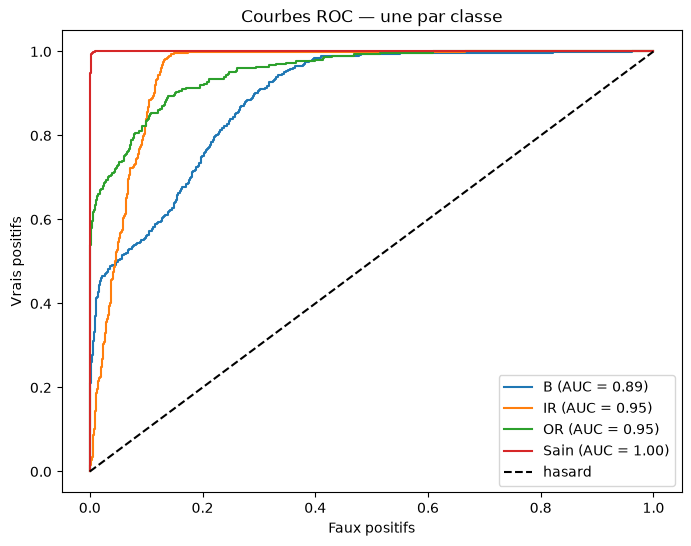

In [36]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Probabilités prédites (une colonne par classe)
probs = logreg.predict_proba(X_test)

# Vraies classes en 0/1 (une colonne par classe)
classes = logreg.classes_
y_bin = label_binarize(y_test, classes=classes)

# Courbes ROC par classe
plt.figure(figsize=(8, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("Faux positifs")
plt.ylabel("Vrais positifs")
plt.title("Courbes ROC — une par classe")
plt.legend()
plt.show()

In [37]:
#| label: arbre de décision : def+fit
from sklearn.tree import DecisionTreeClassifier

Model_tree = DecisionTreeClassifier(criterion='entropy', max_depth=8, random_state=123)
Model_tree.fit(X_train, y_train)
y_pred = Model_tree.predict(X_test)

In [38]:
#| label: arbre de décision : results
print("##########################################")
print("############## Decision tree #############")
print("##########################################")

display(pd.crosstab(y_test, y_pred, rownames=['real'], colnames=['pred']))

print(classification_report(y_test, y_pred))

feats = {}
for feature, importance in zip(X_test.columns, Model_tree.feature_importances_):
    feats[feature] = importance
importances = pd.DataFrame.from_dict(feats, orient='index')
importances = importances.rename(columns={0:'Importance'})
importances = importances.sort_values('Importance', ascending=False)
display(importances[importances['Importance'] != 0])
display(importances[importances['Importance'] == 0])

##########################################
############## Decision tree #############
##########################################


pred,B,IR,OR,Sain
real,,,,
B,469,6,111,14
IR,172,428,0,0
OR,45,0,255,0
Sain,9,0,4,693


              precision    recall  f1-score   support

           B       0.67      0.78      0.72       600
          IR       0.99      0.71      0.83       600
          OR       0.69      0.85      0.76       300
        Sain       0.98      0.98      0.98       706

    accuracy                           0.84      2206
   macro avg       0.83      0.83      0.82      2206
weighted avg       0.86      0.84      0.84      2206



,Importance
amp_BSF_1,0.408242
ratio_BPFI,0.263350
Pic,0.114322
RMS,0.096920
amp_BPFI_1,0.081115
Kurtosis,0.015298
amp_BPFO_1,0.005466
amp_FTF_3,0.004101
amp_FTF_2,0.003807
ratio_BSF,0.002153


,Importance
Crete,0.0
amp_BPFI_2,0.0
amp_BPFO_2,0.0
amp_FTF_1,0.0
ratio_BPFO,0.0
ratio_FTF,0.0


##########################################
######### LogReg VS Random Forest ########
##########################################


,train,test
defaut,,
Sain,601,706
IR,601,600
B,601,600
OR,601,300


=== LogReg ===
Accuracy          : 0.756
Balanced accuracy : 0.736
F1-macro          : 0.734

Rapport par classe :
              precision    recall  f1-score   support

           B       0.56      0.84      0.68       600
          IR       0.80      0.42      0.55       600
          OR       0.78      0.68      0.73       300
        Sain       0.96      1.00      0.98       706

    accuracy                           0.76      2206
   macro avg       0.78      0.74      0.73      2206
weighted avg       0.79      0.76      0.75      2206



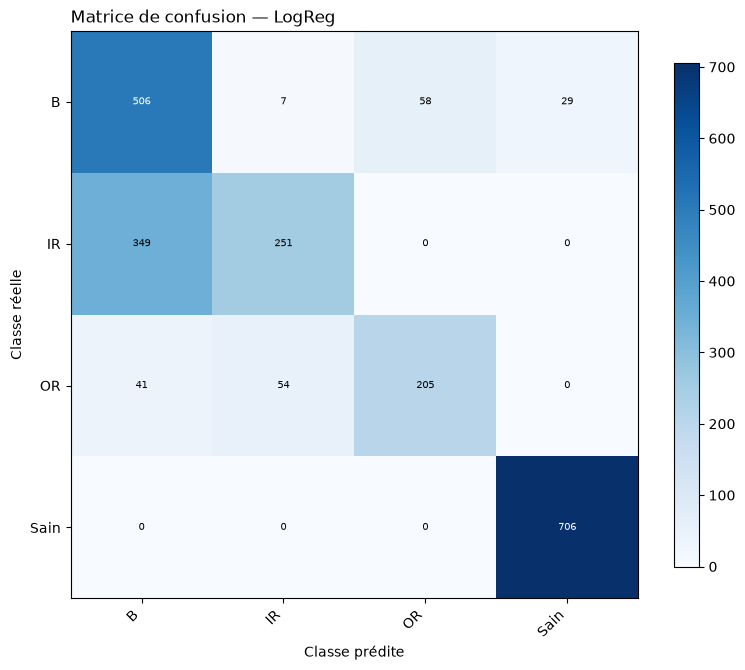

=== Random Forest ===
Accuracy          : 0.842
Balanced accuracy : 0.835
F1-macro          : 0.828

Rapport par classe :
              precision    recall  f1-score   support

           B       0.69      0.83      0.75       600
          IR       0.95      0.68      0.79       600
          OR       0.72      0.84      0.77       300
        Sain       1.00      1.00      1.00       706

    accuracy                           0.84      2206
   macro avg       0.84      0.83      0.83      2206
weighted avg       0.86      0.84      0.84      2206



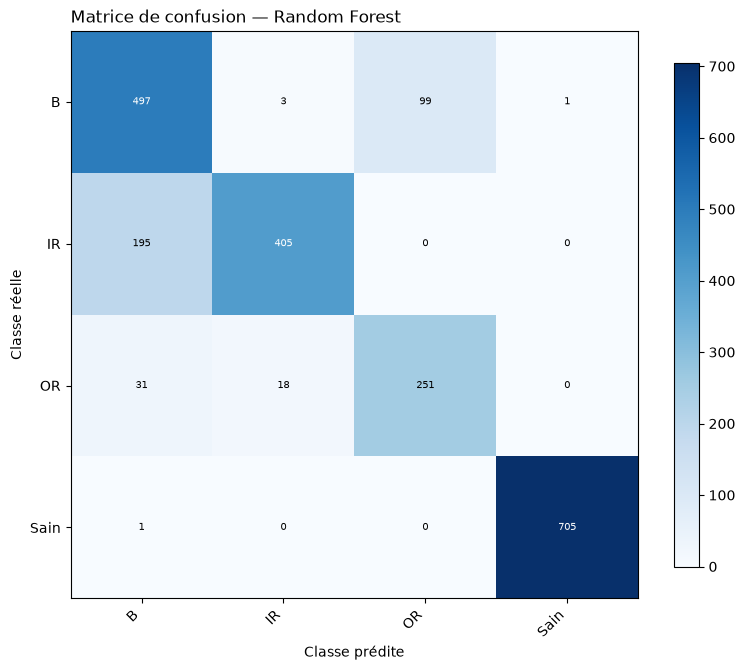

,modèle,accuracy,balanced_acc,F1-macro
0,LogReg,0.756,0.736,0.734
1,Random Forest,0.842,0.835,0.828


In [20]:
# Cellule d'imports (avec les autres)
from Sources import data, features, indicateurs, models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("##########################################")
print("######### LogReg VS Random Forest ########")
print("##########################################")

# Après ton split :
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, indicateurs.COLONNES_INDICATEURS)
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, indicateurs.COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target="defaut")

# Équilibre les datasets
X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

# Eval 1 model :
# logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
# logreg.fit(X_train, y_train)
# y_pred = logreg.predict(X_test)
# models.evaluer_modele(y_test, y_pred, classes=logreg.classes_, titre="LogReg DE→FE")

# compare plusieurs model
modeles = {
    "LogReg": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
}
tableau = models.entrainer_comparer(modeles, X_train, y_train, X_test, y_test)
tableau

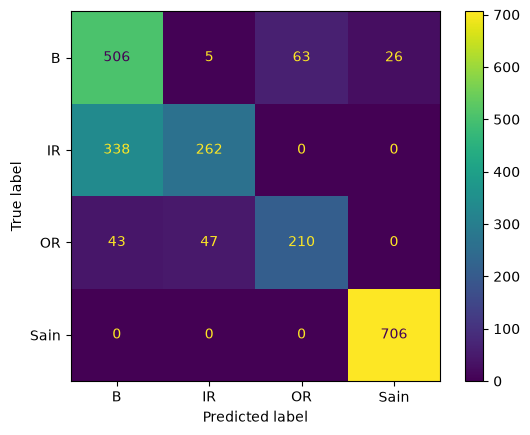

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(modeles["LogReg"], X_test, y_test)
plt.show()